# 06 – Genre and juvenile-marker classification: dummy baselines and classical models

Phase 2 of the popularity project (the popularity notebooks are unchanged). Data: `data/popularity_training_clean.csv` (17,727 items; no scraping). Two tasks, each **without** and **with** the description text:

1. **Genre** – science fiction / fantasy / mystery-thriller. Main experiment on the **clearly single-genre** records only (exactly one genre flag; 16,515 items). Genre labels are rule-based from subject tags, so they are a catalogue label, not a verdict by a reader.
2. **Juvenile marker** – `juvenile = 1` when a subject tag marks the item as juvenile. **`juvenile = 0` only means the catalogue lacks that marker; it does not mean the book is definitely for adults.** The classes are uneven (about 27 % marked), so besides accuracy and macro-F1 we report balanced accuracy and juvenile-class precision / recall / F1 (and ROC-AUC).

**Variant A** = metadata: title words (TF-IDF), creators (one-hot), publication year, scanned pages, archive age, number of creators and number of title words. **Variant B** = exactly the same, plus the description text (nothing else differs).

**Leakage rule.** Both labels are derived from subject tags, so *no subject-derived column is a model input*: not the subject tags, their count, the genre flags, `genre_primary`, `juvenile`, `sampling_stratum` or the collection flag. IDs and provenance fields are excluded too. The `Features` class refuses any column outside the allowed list (checked in the cell below). Genre and juvenile are related in the catalogue (fantasy items carry the marker more often); that relationship is *not* given to the models.

**Protocol.** One saved grouped split per task (group = `ol_group`; 5 grouped, stratified CV folds on 80 % of the work groups; the other 20 % locked as the test set). Thresholds, scalers, TF-IDF, SVD and early stopping use training rows only. Models are chosen with CV macro-F1 and the choice is written to disk **before** the test set is scored. Juvenile models use balanced class weights; no decision threshold is tuned. This notebook: dummy baselines and non-neural models (LogisticRegression, LinearSVC, HistGradientBoosting).

In [1]:
import json, time, warnings, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))
import phase2_experiment as p2
FAMILY = "classical"
P = p2.OUT; P.mkdir(parents=True, exist_ok=True); FIG = P / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_colwidth", 60, "display.max_rows", 200)
env = p2.environment(); (P / "environment_phase2.json").write_text(json.dumps(env, indent=2), encoding="utf-8")
print(json.dumps({k: env[k] for k in ("python", "scikit-learn", "torch", "numpy", "pandas", "device", "cpu_count", "seed", "mlp_seeds")}))
TASKS = ["genre", "juvenile"]

{"python": "3.13.2", "scikit-learn": "1.6.1", "torch": "2.14.0+cpu", "numpy": "2.2.3", "pandas": "2.2.3", "device": "cpu", "cpu_count": 16, "seed": 2026, "mlp_seeds": [2026, 2027, 2028]}


## 1. Eligible books and the leakage guard

In [2]:
df = p2.load_cohort()
D = {t: p2.task_frame(df, t) for t in TASKS}
for t in TASKS:
    c = np.bincount(D[t].y, minlength=len(p2.TASKS[t]["classes"]))
    print(f"{t}: {len(D[t]):,} items, {D[t].ol_group.nunique():,} works; class counts {dict(zip(p2.TASKS[t]['classes'], c.tolist()))}; majority-class share {c.max()/c.sum():.3f}")
multi = df[["genre_science_fiction", "genre_fantasy", "genre_mystery_thriller"]].sum(1)
print("genre flags per item in the full cohort (0 / 1 / 2 / 3 flags):", multi.value_counts().sort_index().to_dict(), "-> only the 1-flag records are used for genre")
print("\nMODEL INPUTS  :", p2.ALLOWED_COLS)
print("NEVER INPUTS  :", p2.EXCLUDED)
sample = p2.allowed(D["genre"].head(50)); assert set(sample.columns) == set(p2.ALLOWED_COLS) and not (set(p2.EXCLUDED) & set(sample.columns))
for w in ("juvenile",):
    print(f"\nthe word '{w}' appears in {int(df.title_text.str.contains(w).sum())} titles and {int(df.description.str.lower().str.contains(w).sum())} descriptions (of 17,727): no catalogue marker leaks through the text.")

genre: 16,515 items, 15,555 works; class counts {'science_fiction': 4748, 'fantasy': 5888, 'mystery_thriller': 5879}; majority-class share 0.357
juvenile: 17,727 items, 16,666 works; class counts {'no_marker': 12855, 'juvenile_marker': 4872}; majority-class share 0.725
genre flags per item in the full cohort (0 / 1 / 2 / 3 flags): {0: 40, 1: 16515, 2: 1127, 3: 45} -> only the 1-flag records are used for genre

MODEL INPUTS  : ['publication_year', 'log_pages', 'age_years', 'n_creators', 'title_words', 'title_text', 'creator_tokens', 'description']
NEVER INPUTS  : ['subjects', 'n_subjects', 'juvenile', 'genre_primary', 'genre_science_fiction', 'genre_fantasy', 'genre_mystery_thriller', 'sampling_stratum', 'in_americana', 'source_batch', 'identifier', 'ol_group', 'work_group', 'views_all_time', 'description_words']

the word 'juvenile' appears in 0 titles and 27 descriptions (of 17,727): no catalogue marker leaks through the text.


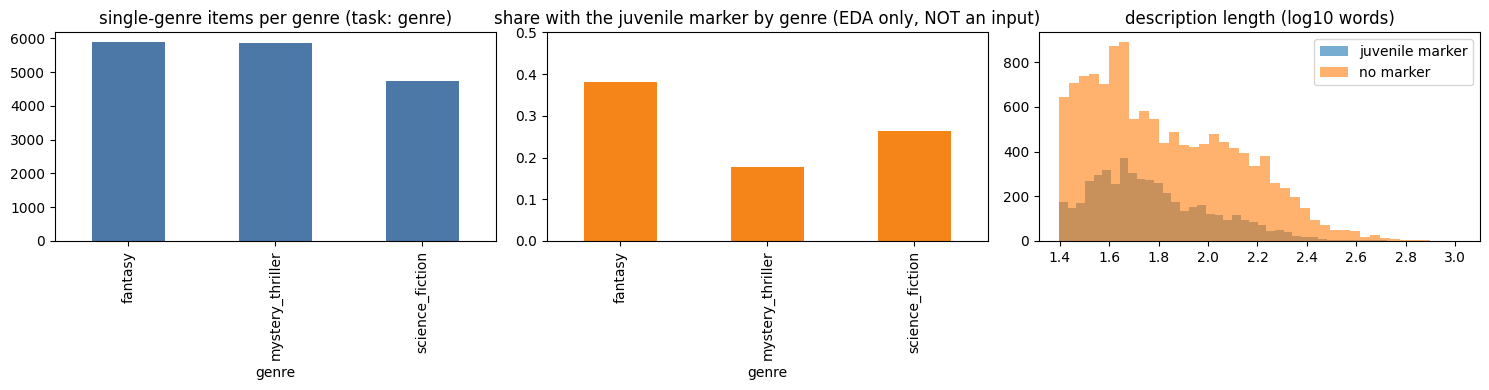

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
g = D["genre"]; g.assign(genre=[p2.GENRES[i] for i in g.y]).genre.value_counts().plot.bar(ax=ax[0], color="#4c78a8"); ax[0].set(title="single-genre items per genre (task: genre)")
jt = df.assign(genre=np.select([df.genre_science_fiction == 1, df.genre_fantasy == 1, df.genre_mystery_thriller == 1], p2.GENRES, "none")).query("genre != 'none'").groupby("genre").juvenile.mean()
jt.plot.bar(ax=ax[1], color="#f58518"); ax[1].set(title="share with the juvenile marker by genre (EDA only, NOT an input)", ylim=(0, .5))
for lab, s in (("juvenile marker", df[df.juvenile == 1]), ("no marker", df[df.juvenile == 0])):
    ax[2].hist(np.log10(s.description_words.clip(lower=1)), bins=40, alpha=.6, label=lab)
ax[2].set(title="description length (log10 words)"); ax[2].legend()
plt.tight_layout(); plt.savefig(FIG / f"phase2_eda.png", dpi=130); plt.show()

## 2. Saved grouped splits (written before any model is fitted)

In [4]:
MAN = {t: p2.build_split(t, D[t], force=True) for t in TASKS}

In [5]:
for t in TASKS:
    m = MAN[t].copy(); m["label"] = [p2.TASKS[t]["classes"][i] for i in m.y]
    print(f"--- {t}: split sizes (rows / works), class counts"); display(pd.concat([m.groupby("split").agg(rows=("identifier", "size"), works=("ol_group", "nunique")), pd.crosstab(m.split, m.label)], axis=1))
    assert not (set(m[m.split == "test"].ol_group) & set(m[m.split == "pool"].ol_group))
    print(pd.crosstab(m[m.split == "pool"].cv_fold, m[m.split == "pool"].label).to_string())

--- genre: split sizes (rows / works), class counts


,rows,works,fantasy,mystery_thriller,science_fiction
split,,,,,
pool,13226,12443,4710,4688,3828
test,3289,3112,1178,1191,920


label    fantasy  mystery_thriller  science_fiction
cv_fold                                            
0            968               918              768
1            912               965              756
2            958               909              772
3            957               951              747
4            915               945              785
--- juvenile: split sizes (rows / works), class counts


,rows,works,juvenile_marker,no_marker
split,,,,
pool,14182,13329,3888,10294
test,3545,3337,984,2561


label    juvenile_marker  no_marker
cv_fold                            
0                    808       2033
1                    752       2093
2                    748       2083
3                    775       2065
4                    805       2020


## 3. Grouped cross-validation on the training pool

In [6]:
CV, SUM = {}, {}
for t in TASKS:
    t0 = time.time(); CV[t] = p2.run_cv(t, D[t], MAN[t], FAMILY, n_jobs=5, force=True)
    res = CV[t]["results"]; res.round(5).to_csv(P / f"{t}_{FAMILY}_cv_all_folds.csv", index=False)
    SUM[t] = p2.summarise_cv(res); SUM[t].round(5).to_csv(P / f"{t}_{FAMILY}_cv_summary.csv", index=False)
    print(f"{t}: cross-validation done in {time.time() - t0:.0f} s (dummy, logreg, linsvc, hgb)")

genre: cross-validation done in 157 s (dummy, logreg, linsvc, hgb)


juvenile: cross-validation done in 61 s (dummy, logreg, linsvc, hgb)


In [7]:
for t in TASKS:
    s = SUM[t].copy(); s["setting"] = s.algo + " " + s.cfg_id.astype(str)
    vals = ["accuracy", "macro_f1"] + (["balanced_accuracy", "juv_f1"] if t == "juvenile" else [])
    print(f"=== {t}: CV mean over 5 grouped folds"); display(s.pivot(index="setting", columns="variant", values=vals).round(4))

=== genre: CV mean over 5 grouped folds


accuracy         macro_f1        
variant         A       B        A       B
setting                                   
dummy 0    0.3486  0.3486   0.1723  0.1723
hgb 0      0.6086  0.7932   0.6017  0.7886
hgb 1      0.6208  0.8036   0.6147  0.7993
hgb 2      0.6347  0.8110   0.6299  0.8071
linsvc 0   0.6724  0.8409   0.6650  0.8366
linsvc 1   0.6906  0.8534   0.6858  0.8503
linsvc 2   0.6885  0.8538   0.6845  0.8510
linsvc 3   0.6751  0.8442   0.6713  0.8414
logreg 0   0.6827  0.8461   0.6772  0.8427
logreg 1   0.6908  0.8537   0.6865  0.8510
logreg 2   0.6844  0.8521   0.6805  0.8495
logreg 3   0.6741  0.8477   0.6705  0.8452

=== juvenile: CV mean over 5 grouped folds


accuracy         macro_f1         balanced_accuracy          juv_f1        
variant         A       B        A       B                 A       B       A       B
setting                                                                             
dummy 0    0.7258  0.7258   0.4206  0.4206            0.5000  0.5000  0.0000  0.0000
hgb 0      0.6735  0.7919   0.6541  0.7600            0.7120  0.7883  0.5722  0.6725
hgb 1      0.6912  0.8028   0.6672  0.7692            0.7162  0.7924  0.5780  0.6812
hgb 2      0.7163  0.8136   0.6826  0.7760            0.7152  0.7900  0.5792  0.6843
linsvc 0   0.6938  0.7897   0.6634  0.7551            0.7012  0.7791  0.5622  0.6631
linsvc 1   0.7154  0.8035   0.6754  0.7647            0.6997  0.7793  0.5614  0.6692
linsvc 2   0.7202  0.8014   0.6698  0.7568            0.6833  0.7642  0.5409  0.6528
linsvc 3   0.7146  0.7919   0.6571  0.7402            0.6656  0.7419  0.5168  0.6243
logreg 0   0.6980  0.7908   0.6657  0.7554            0.7007  0.7780  0.5618  0.6625
logreg 1   0.7168  0.8037   0.6758  0.7640            0.6989  0.7771  0.5606  0.6671
logreg 2   0.7215  0.8041   0.6708  0.7600            0.6839  0.7671  0.5416  0.6570
logreg 3   0.7180  0.7995   0.6595  0.7506            0.6671  0.7534  0.5185  0.6402

### Model choice from CV only
Best configuration of each algorithm per variant by CV macro-F1; the selection is saved now, **before the test set is touched**.

In [8]:
SEL = {}
for t in TASKS:
    SEL[t] = p2.select_models(SUM[t]); SEL[t].round(5).to_csv(P / f"{t}_{FAMILY}_cv_selection.csv", index=False)
(P / f"selection_{FAMILY}_written_utc.txt").write_text(pd.Timestamp.utcnow().isoformat())
for t in TASKS:
    print("===", t); display(SEL[t][["variant", "algo", "family", "cfg", "cv_macro_f1", "cv_accuracy", "is_best_in_family"]].round(4))

=== genre


,variant,algo,family,cfg,cv_macro_f1,cv_accuracy,is_best_in_family
0,A,dummy,baseline,{},0.1723,0.3486,False
1,A,hgb,tree,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",0.6299,0.6347,False
2,A,linsvc,linear,"{""C"": 0.1}",0.6858,0.6906,False
3,A,logreg,linear,"{""C"": 1.0}",0.6865,0.6908,True
4,B,dummy,baseline,{},0.1723,0.3486,False
5,B,hgb,tree,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",0.8071,0.8110,False
6,B,linsvc,linear,"{""C"": 0.3}",0.8510,0.8538,True
7,B,logreg,linear,"{""C"": 1.0}",0.8510,0.8537,False


=== juvenile


,variant,algo,family,cfg,cv_macro_f1,cv_accuracy,is_best_in_family
0,A,dummy,baseline,{},0.4206,0.7258,False
1,A,hgb,tree,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",0.6826,0.7163,True
2,A,linsvc,linear,"{""C"": 0.1}",0.6754,0.7154,False
3,A,logreg,linear,"{""C"": 1.0}",0.6758,0.7168,False
4,B,dummy,baseline,{},0.4206,0.7258,False
5,B,hgb,tree,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",0.7760,0.8136,True
6,B,linsvc,linear,"{""C"": 0.1}",0.7647,0.8035,False
7,B,logreg,linear,"{""C"": 1.0}",0.7640,0.8037,False


In [9]:
rows = []
for t in TASKS:
    r = CV[t]["results"]; r = r[r.seed.astype(str).isin(["single", "avg"])]
    for s in SEL[t].itertuples():
        pass
    for a in SEL[t].algo.unique():
        ca = int(SEL[t][(SEL[t].variant == "A") & (SEL[t].algo == a)].cfg_id.iloc[0]); cb = int(SEL[t][(SEL[t].variant == "B") & (SEL[t].algo == a)].cfg_id.iloc[0])
        ra = r[(r.variant == "A") & (r.algo == a) & (r.cfg_id == ca)].sort_values("fold"); rb = r[(r.variant == "B") & (r.algo == a) & (r.cfg_id == cb)].sort_values("fold")
        for c in ["accuracy", "macro_f1"] + (["balanced_accuracy", "juv_f1"] if t == "juvenile" else []):
            d = rb[c].to_numpy() - ra[c].to_numpy()
            rows.append({"task": t, "algo": a, "metric": c, "A_mean": ra[c].mean(), "B_mean": rb[c].mean(), "mean_B_minus_A": d.mean(), "sd_of_fold_differences": d.std(ddof=1), "folds_B_better": int((d > 0).sum())})
PC = pd.DataFrame(rows); PC.round(4).to_csv(P / f"cv_paired_A_vs_B_{FAMILY}.csv", index=False)
print("Description effect inside CV (B minus A, same algorithm, same five folds)"); display(PC.round(4))

Description effect inside CV (B minus A, same algorithm, same five folds)


,task,algo,metric,A_mean,B_mean,mean_B_minus_A,sd_of_fold_differences,folds_B_better
0,genre,dummy,accuracy,0.3486,0.3486,0.0000,0.0000,0
1,genre,dummy,macro_f1,0.1723,0.1723,0.0000,0.0000,0
2,genre,hgb,accuracy,0.6347,0.8110,0.1762,0.0101,5
3,genre,hgb,macro_f1,0.6299,0.8071,0.1772,0.0110,5
4,genre,linsvc,accuracy,0.6906,0.8538,0.1632,0.0062,5
5,genre,linsvc,macro_f1,0.6858,0.8510,0.1652,0.0064,5
6,genre,logreg,accuracy,0.6908,0.8537,0.1629,0.0101,5
7,genre,logreg,macro_f1,0.6865,0.8510,0.1645,0.0105,5
8,juvenile,dummy,accuracy,0.7258,0.7258,0.0000,0.0000,0
9,juvenile,dummy,macro_f1,0.4206,0.4206,0.0000,0.0000,0


## 4. Locked test set (selected configurations refit on the whole training pool)

In [10]:
TEST, TT = {}, {}
for t in TASKS:
    t0 = time.time(); TEST[t] = p2.run_test(t, D[t], MAN[t], SEL[t], FAMILY, force=True); TT[t] = p2.test_tables(t, TEST[t], SEL[t])
    TT[t]["table"].round(5).to_csv(P / f"{t}_{FAMILY}_test_results.csv", index=False); TT[t]["confusion"].to_csv(P / f"{t}_{FAMILY}_test_confusion.csv", index=False)
    if len(TT[t]["seeds"]): TT[t]["seeds"].round(5).to_csv(P / f"{t}_{FAMILY}_test_seed_variability.csv", index=False)
    p2.predictions_frame(t, TEST[t], TT[t]["scores"], D[t]).to_csv(P / f"{t}_{FAMILY}_test_predictions.csv", index=False)
    np.savez_compressed(P / f"{t}_{FAMILY}_test_scores.npz", ids=np.array(TEST[t]["test_identifiers"]), **{f"{v}__{a}": s for (v, a), s in TT[t]["scores"].items()})
    print(f"{t}: test done in {time.time() - t0:.0f} s; train pool {TEST[t]['pool_rows']:,} / test {TEST[t]['test_rows']:,} items; class counts in test {np.bincount(TEST[t]['test_y']).tolist()}")

  File "C:\Users\mhmd2\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python313\Lib\subprocess.py", line 1038, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Python313\Lib\subprocess.py", line 1550, i

genre: test done in 42 s; train pool 13,226 / test 3,289 items; class counts in test [920, 1178, 1191]


juvenile: test done in 17 s; train pool 14,182 / test 3,545 items; class counts in test [2561, 984]


In [11]:
for t in TASKS:
    tab = TT[t]["table"]; cols = ["accuracy", "macro_f1"] + (["balanced_accuracy", "juv_precision", "juv_recall", "juv_f1", "roc_auc"] if t == "juvenile" else [f"f1_{g}" for g in p2.GENRES])
    print(f"=== TEST {t}: dummy = train-fitted baseline (always the most common training class)")
    display(tab.pivot(index="algo", columns="variant", values=cols).round(4))
    print("CV-chosen best in this family per variant:"); display(tab[tab.is_best_in_family][["variant", "algo", "cfg", "accuracy", "macro_f1"]].round(4))

=== TEST genre: dummy = train-fitted baseline (always the most common training class)


accuracy         macro_f1         f1_science_fiction         f1_fantasy         f1_mystery_thriller        
variant        A       B        A       B                  A       B          A       B                   A       B
algo                                                                                                               
dummy     0.3582  0.3582   0.1758  0.1758             0.0000  0.0000     0.5274  0.5274              0.0000  0.0000
hgb       0.6254  0.8042   0.6198  0.7990             0.5728  0.7474     0.6075  0.7919              0.6790  0.8576
linsvc    0.7084  0.8626   0.7027  0.8595             0.6558  0.8271     0.7116  0.8513              0.7408  0.9001
logreg    0.7078  0.8614   0.7020  0.8581             0.6527  0.8242     0.7115  0.8475              0.7417  0.9026

CV-chosen best in this family per variant:


,variant,algo,cfg,accuracy,macro_f1
3,A,logreg,"{""C"": 1.0}",0.7078,0.7020
6,B,linsvc,"{""C"": 0.3}",0.8626,0.8595


=== TEST juvenile: dummy = train-fitted baseline (always the most common training class)


accuracy         macro_f1         balanced_accuracy         juv_precision         juv_recall          juv_f1         roc_auc        
variant        A       B        A       B                 A       B             A       B          A       B       A       B       A       B
algo                                                                                                                                        
dummy     0.7224  0.7224   0.4194  0.4194            0.5000  0.5000        0.0000  0.0000     0.0000  0.0000  0.0000  0.0000  0.5000  0.5000
hgb       0.7193  0.8254   0.6881  0.7924            0.7213  0.8078        0.4962  0.6591     0.7256  0.7683  0.5894  0.7095  0.8055  0.8957
linsvc    0.7278  0.8164   0.6900  0.7825            0.7137  0.7991        0.5072  0.6432     0.6819  0.7602  0.5817  0.6968  0.7941  0.8774
logreg    0.7278  0.8161   0.6890  0.7811            0.7115  0.7957        0.5073  0.6451     0.6748  0.7500  0.5792  0.6936  0.7936  0.8771

CV-chosen best in this family per variant:


,variant,algo,cfg,accuracy,macro_f1
1,A,hgb,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",0.7193,0.6881
5,B,hgb,"{""max_iter"": 200, ""learning_rate"": 0.05, ""max_depth"": 6,...",0.8254,0.7924


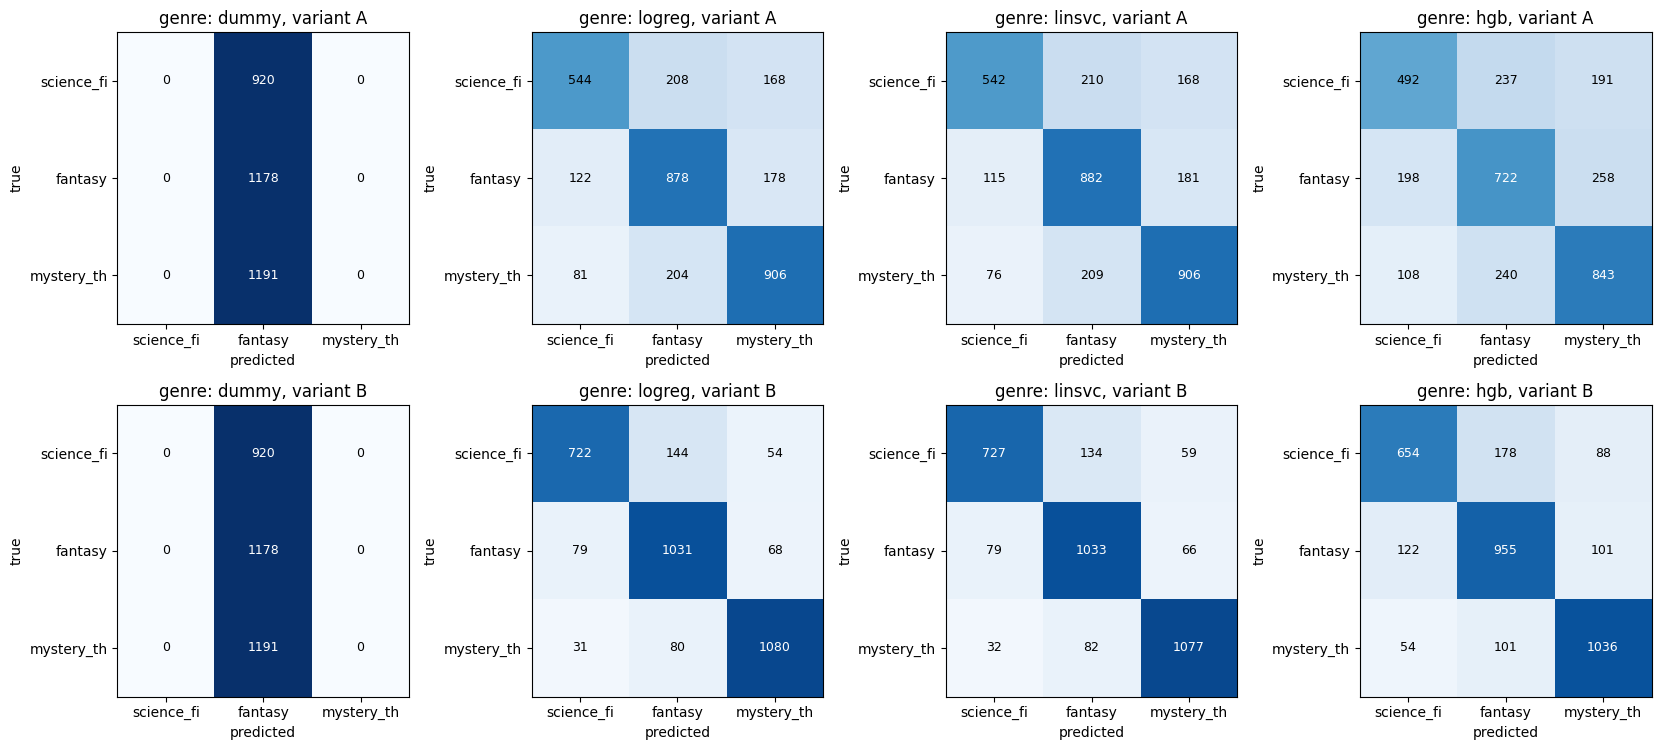

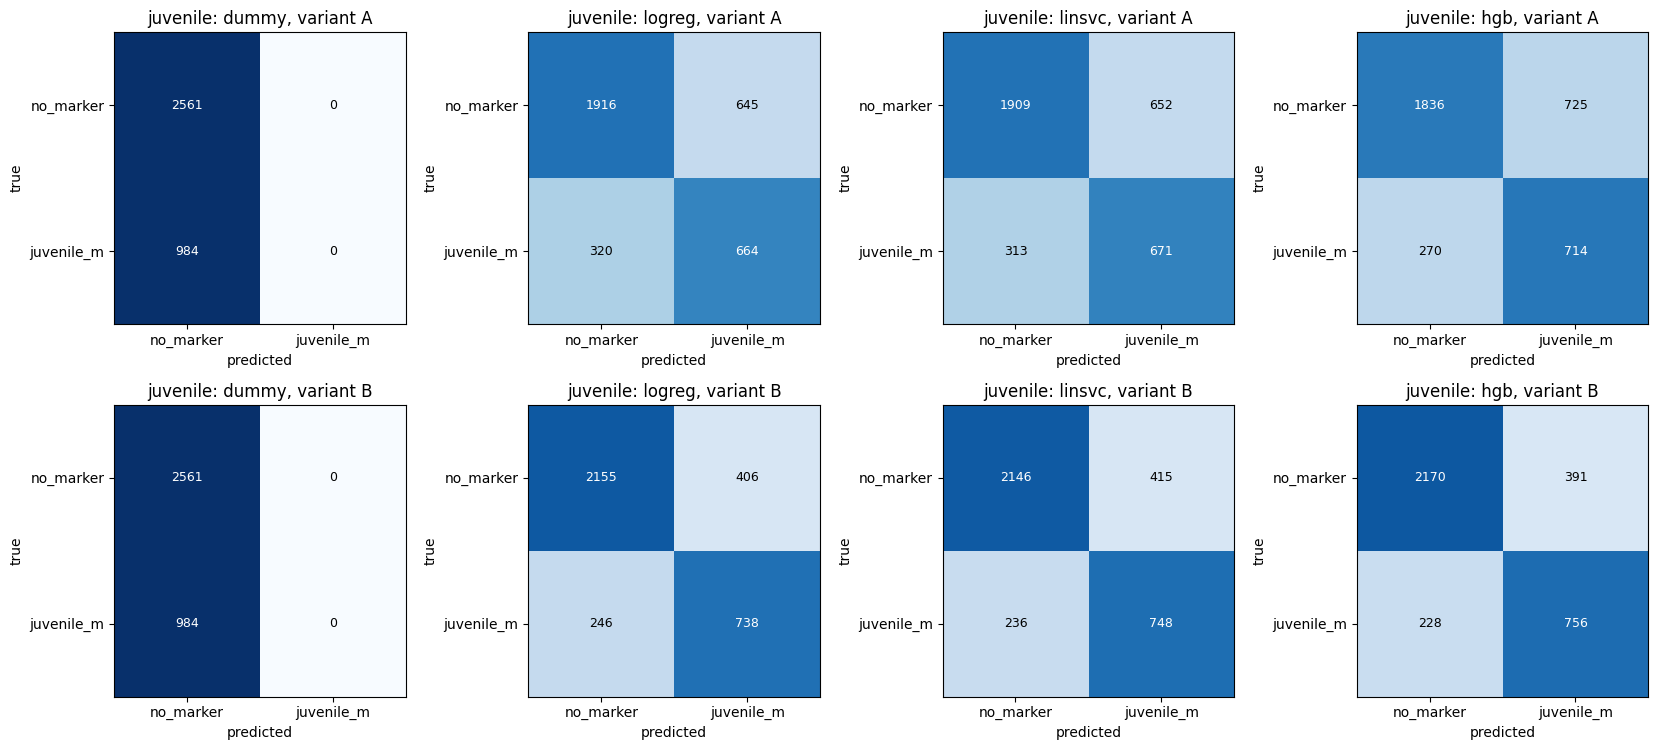

In [12]:
cm = {t: TT[t]["confusion"] for t in TASKS}
shown = [a for a in (["dummy", "logreg", "linsvc", "hgb"] if FAMILY == "classical" else ["mlp"])]
for t in TASKS:
    K = len(p2.TASKS[t]["classes"]); cls = p2.TASKS[t]["classes"]
    fig, ax = plt.subplots(2, len(shown), figsize=(4.2 * len(shown), 7.6), squeeze=False)
    for i, v in enumerate(p2.VARIANTS):
        for j, a in enumerate(shown):
            x = cm[t][(cm[t].variant == v) & (cm[t].algo == a)].set_index("true_class").loc[cls][[f"pred_{c}" for c in cls]].to_numpy()
            ax[i, j].imshow(x / x.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
            for p in range(K):
                for q in range(K): ax[i, j].text(q, p, str(x[p, q]), ha="center", va="center", color="black" if x[p, q] / x[p].sum() < .6 else "white", fontsize=9)
            ax[i, j].set(xticks=range(K), yticks=range(K), xticklabels=[c[:10] for c in cls], yticklabels=[c[:10] for c in cls], title=f"{t}: {a}, variant {v}", xlabel="predicted", ylabel="true")
    plt.tight_layout(); plt.savefig(FIG / f"phase2_confusion_{t}_{FAMILY}.png", dpi=130); plt.show()

In [13]:
for t in TASKS:
    tab = TT[t]["table"]; ca = [c for c in tab.columns if "|" in c]
    print(f"=== {t}: does the result depend on author names? Test items whose creator also appears in the training pool: {TT[t]['n_author_seen']:,}; creator NOT seen: {TT[t]['n_author_unseen']:,}")
    display(tab[tab.is_best_in_family | (tab.algo == "dummy")][["variant", "algo", "accuracy", "macro_f1"] + ca].round(4))

=== genre: does the result depend on author names? Test items whose creator also appears in the training pool: 1,823; creator NOT seen: 1,466


,variant,algo,accuracy,macro_f1,accuracy | author seen in training,macro_f1 | author seen in training,accuracy | author NOT seen in training,macro_f1 | author NOT seen in training
0,A,dummy,0.3582,0.1758,0.3582,0.1758,0.3581,0.1758
3,A,logreg,0.7078,0.7020,0.7976,0.7961,0.5962,0.5726
4,B,dummy,0.3582,0.1758,0.3582,0.1758,0.3581,0.1758
6,B,linsvc,0.8626,0.8595,0.8974,0.8969,0.8192,0.8089


=== juvenile: does the result depend on author names? Test items whose creator also appears in the training pool: 2,027; creator NOT seen: 1,518


,variant,algo,accuracy,macro_f1,accuracy | author seen in training,macro_f1 | author seen in training,accuracy | author NOT seen in training,macro_f1 | author NOT seen in training
0,A,dummy,0.7224,0.4194,0.6976,0.4109,0.7556,0.4304
1,A,hgb,0.7193,0.6881,0.7425,0.7152,0.6884,0.6513
4,B,dummy,0.7224,0.4194,0.6976,0.4109,0.7556,0.4304
5,B,hgb,0.8254,0.7924,0.8254,0.7994,0.8254,0.7808


### Is a difference reliable? Group-level bootstrap on the test set (1,000 resamples of work groups)
Same test items for A and B. Intervals that include 0 are not distinguishable from noise on this test set.

In [14]:
BOOT = {}
for t in TASKS:
    y, g, sc = TEST[t]["test_y"], TEST[t]["test_groups"], TT[t]["scores"]; pr = {k: v.argmax(1) for k, v in sc.items()}
    selt = SEL[t]; win = {v: selt[(selt.variant == v) & selt.is_best_in_family].iloc[0].algo for v in p2.VARIANTS}
    pairs = [("description effect (B - A), same algorithm", a, ("A", a), ("B", a)) for a in selt.algo.unique()]
    pairs.append(("CV-selected best classical model (B winner - A winner)", f"{win['B']} (B) vs {win['A']} (A)", ("A", win["A"]), ("B", win["B"])))
    for v in p2.VARIANTS:
        pairs += [(f"model minus train-fitted baseline, variant {v}", a, (v, "dummy"), (v, a)) for a in selt.algo.unique() if a != "dummy"]
    BOOT[t] = p2.bootstrap_comparisons(t, y, g, pr, pairs); BOOT[t].round(5).to_csv(P / f"{t}_{FAMILY}_test_bootstrap.csv", index=False)
    keep = ["comparison", "detail", "accuracy_mean", "accuracy_lo95", "accuracy_hi95", "macro_f1_mean", "macro_f1_lo95", "macro_f1_hi95"] + (["balanced_accuracy_mean", "balanced_accuracy_lo95", "balanced_accuracy_hi95", "juv_f1_mean", "juv_f1_lo95", "juv_f1_hi95"] if t == "juvenile" else [])
    print("===", t, "(second minus first)"); display(BOOT[t][keep].round(4))

=== genre (second minus first)


,comparison,detail,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95
0,"description effect (B - A), same algorithm",dummy,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,"description effect (B - A), same algorithm",hgb,0.1785,0.1599,0.1978,0.1790,0.1601,0.1988
2,"description effect (B - A), same algorithm",linsvc,0.1537,0.1380,0.1688,0.1564,0.1402,0.1719
3,"description effect (B - A), same algorithm",logreg,0.1533,0.1378,0.1690,0.1559,0.1398,0.1724
4,CV-selected best classical model (B winner - A winner),linsvc (B) vs logreg (A),0.1544,0.1388,0.1696,0.1572,0.1418,0.1724
5,"model minus train-fitted baseline, variant A",hgb,0.2671,0.2427,0.2910,0.4439,0.4264,0.4611
6,"model minus train-fitted baseline, variant A",linsvc,0.3505,0.3284,0.3720,0.5272,0.5097,0.5452
7,"model minus train-fitted baseline, variant A",logreg,0.3499,0.3276,0.3711,0.5265,0.5088,0.5440
8,"model minus train-fitted baseline, variant B",hgb,0.4457,0.4232,0.4675,0.6230,0.6073,0.6388
9,"model minus train-fitted baseline, variant B",linsvc,0.5042,0.4843,0.5248,0.6837,0.6695,0.6968


=== juvenile (second minus first)


,comparison,detail,accuracy_mean,accuracy_lo95,accuracy_hi95,macro_f1_mean,macro_f1_lo95,macro_f1_hi95,balanced_accuracy_mean,balanced_accuracy_lo95,balanced_accuracy_hi95,juv_f1_mean,juv_f1_lo95,juv_f1_hi95
0,"description effect (B - A), same algorithm",dummy,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,"description effect (B - A), same algorithm",hgb,0.1057,0.0902,0.1221,0.1040,0.0868,0.1212,0.0862,0.0684,0.1035,0.1198,0.0968,0.1418
2,"description effect (B - A), same algorithm",linsvc,0.0890,0.0757,0.1022,0.0930,0.0787,0.1071,0.0857,0.0712,0.1003,0.1156,0.0971,0.1346
3,"description effect (B - A), same algorithm",logreg,0.0886,0.0752,0.1021,0.0925,0.0780,0.1070,0.0846,0.0702,0.0982,0.1149,0.0965,0.1331
4,CV-selected best classical model (B winner - A winner),hgb (B) vs hgb (A),0.1057,0.0902,0.1221,0.1040,0.0868,0.1212,0.0862,0.0684,0.1035,0.1198,0.0968,0.1418
5,"model minus train-fitted baseline, variant A",hgb,-0.0030,-0.0259,0.0186,0.2687,0.2484,0.2866,0.2215,0.2052,0.2376,0.5894,0.5636,0.6116
6,"model minus train-fitted baseline, variant A",linsvc,0.0051,-0.0167,0.0261,0.2703,0.2514,0.2881,0.2137,0.1964,0.2302,0.5814,0.5572,0.6054
7,"model minus train-fitted baseline, variant A",logreg,0.0051,-0.0164,0.0259,0.2694,0.2500,0.2869,0.2115,0.1949,0.2288,0.5789,0.5553,0.6026
8,"model minus train-fitted baseline, variant B",hgb,0.1027,0.0839,0.1218,0.3727,0.3551,0.3891,0.3077,0.2923,0.3225,0.7092,0.6855,0.7304
9,"model minus train-fitted baseline, variant B",linsvc,0.0941,0.0745,0.1117,0.3633,0.3451,0.3796,0.2994,0.2842,0.3149,0.6970,0.6733,0.7190


## 5. Grouped learning curves (training pool only; the test set is not used)

In [15]:
LC = {}
for t in TASKS:
    t0 = time.time(); LC[t] = p2.run_learning_curves(t, D[t], MAN[t], SEL[t], FAMILY, n_jobs=5, force=True); LC[t].round(5).to_csv(P / f"{t}_{FAMILY}_learning_curves.csv", index=False)
    print(f"{t}: learning curves done in {time.time() - t0:.0f} s")

genre: learning curves done in 225 s


juvenile: learning curves done in 89 s


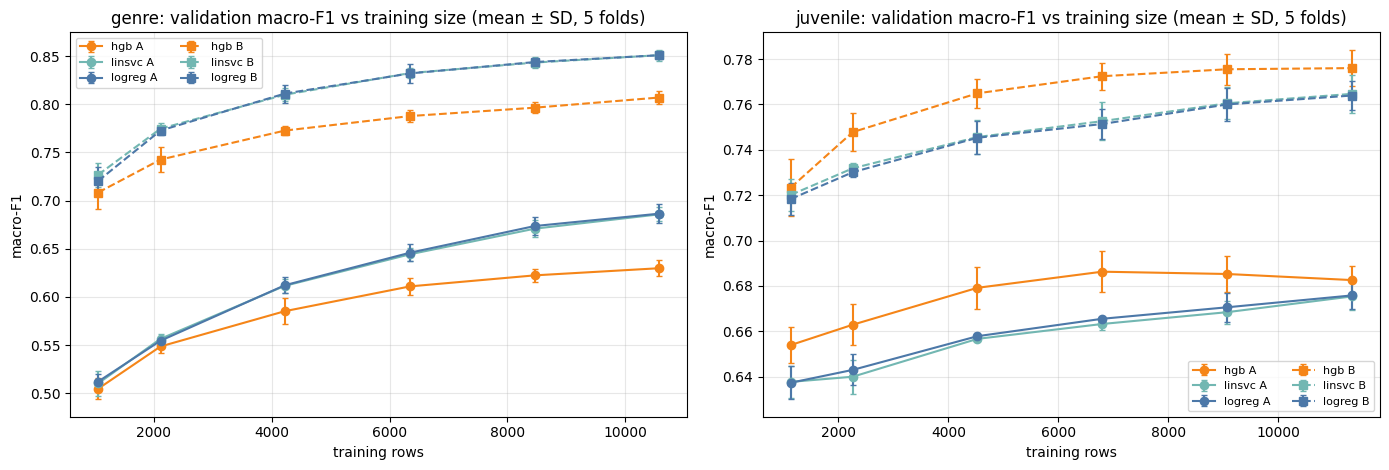

genre


rows                  macro_f1                
fraction           0.2     0.6      1.0      0.2     0.6     1.0
algo   variant                                                  
hgb    A        2113.0  6350.0  10580.8   0.5487  0.6110  0.6299
       B        2113.0  6350.0  10580.8   0.7426  0.7878  0.8071
linsvc A        2113.0  6350.0  10580.8   0.5566  0.6444  0.6858
       B        2113.0  6350.0  10580.8   0.7747  0.8324  0.8510
logreg A        2113.0  6350.0  10580.8   0.5546  0.6460  0.6865
       B        2113.0  6350.0  10580.8   0.7728  0.8321  0.8510

juvenile


rows                  macro_f1                
fraction           0.2     0.6      1.0      0.2     0.6     1.0
algo   variant                                                  
hgb    A        2260.0  6800.4  11345.6   0.6629  0.6863  0.6826
       B        2260.0  6800.4  11345.6   0.7478  0.7725  0.7760
linsvc A        2260.0  6800.4  11345.6   0.6400  0.6632  0.6754
       B        2260.0  6800.4  11345.6   0.7319  0.7526  0.7647
logreg A        2260.0  6800.4  11345.6   0.6430  0.6655  0.6758
       B        2260.0  6800.4  11345.6   0.7301  0.7514  0.7640

In [16]:
col = {"logreg": "#4c78a8", "linsvc": "#72b7b2", "hgb": "#f58518", "mlp": "#54a24b"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for a, t in zip(ax, TASKS):
    frames = [LC[t]] + ([] if FAMILY == "classical" else [LCC[t]])
    for g_ in frames:
        for (v, algo), g in g_.groupby(["variant", "algo"]):
            s = g.groupby("fraction").agg(rows=("train_rows", "mean"), m=("macro_f1", "mean"), sd=("macro_f1", "std"))
            a.errorbar(s.rows, s.m, yerr=s.sd, color=col[algo], ls="-" if v == "A" else "--", marker="o" if v == "A" else "s", capsize=2, label=f"{algo} {v}")
    a.set(title=f"{t}: validation macro-F1 vs training size (mean ± SD, 5 folds)", xlabel="training rows", ylabel="macro-F1"); a.legend(ncol=2, fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / f"phase2_learning_curves_{FAMILY}.png", dpi=130); plt.show()
for t in TASKS:
    x = pd.concat([LC[t]] + ([] if FAMILY == "classical" else [LCC[t]]))
    print(t); display(x[x.fraction.isin([0.2, 0.6, 1.0])].groupby(["algo", "variant", "fraction"]).agg(rows=("train_rows", "mean"), macro_f1=("macro_f1", "mean")).round(4).unstack("fraction"))

## 6. Training times

In [17]:
tt = []
for t in TASKS:
    r = CV[t]["results"]; r = r[r.seed.astype(str).isin(["single", "avg"])].merge(SEL[t][["variant", "algo", "cfg_id"]], on=["variant", "algo", "cfg_id"])
    r = r.assign(per_seed=np.where(r.algo == "mlp", r.fit_seconds / len(p2.MLP_SEEDS), r.fit_seconds))
    x = r.groupby(["algo", "variant"]).agg(cv_fit_s_per_fold=("fit_seconds", "mean"), cv_fit_s_per_seed_or_model=("per_seed", "mean")).round(2)
    fin = TT[t]["table"].set_index(["algo", "variant"]).fit_seconds.round(2).rename("final_fit_s_on_pool")
    x = x.join(fin); x.insert(0, "task", t); tt.append(x.reset_index())
TT_ALL = pd.concat(tt); TT_ALL.to_csv(P / f"training_times_{FAMILY}.csv", index=False); display(TT_ALL)
print("Feature construction (TF-IDF/SVD/scaling for A and B together), seconds: genre/juvenile final fits %.1f / %.1f" % (TEST["genre"]["feature_seconds"], TEST["juvenile"]["feature_seconds"]))
print("MLP fit times in 'cv_fit_s_per_fold' are the sum over the three seeds; CPU only.")

,algo,variant,task,cv_fit_s_per_fold,cv_fit_s_per_seed_or_model,final_fit_s_on_pool
0,dummy,A,genre,0.00,0.00,0.00
1,dummy,B,genre,0.00,0.00,0.00
2,hgb,A,genre,7.28,7.28,3.88
3,hgb,B,genre,26.60,26.60,13.87
4,linsvc,A,genre,0.13,0.13,0.16
5,linsvc,B,genre,17.04,17.04,13.62
6,logreg,A,genre,0.87,0.87,0.87
7,logreg,B,genre,1.99,1.99,2.10
0,dummy,A,juvenile,0.00,0.00,0.00
1,dummy,B,juvenile,0.00,0.00,0.00


Feature construction (TF-IDF/SVD/scaling for A and B together), seconds: genre/juvenile final fits 6.8 / 7.6
MLP fit times in 'cv_fit_s_per_fold' are the sum over the three seeds; CPU only.


## 7. Findings

All numbers are from this executed notebook. Locked test sets: **genre** 3,289 items (920 science fiction / 1,178 fantasy / 1,191 mystery-thriller), **juvenile** 3,545 items (2,561 without / 984 with the marker); training pools 13,226 and 14,182 items; every comparison uses the same items and the same saved grouped folds. Models chosen by CV macro-F1 before the test set was scored: genre – LogisticRegression (A) and LinearSVC (B; tied with LogReg at 0.851); juvenile – HistGradientBoosting in both variants.

| Test set | Dummy baseline | A: metadata | B: metadata + description |
|---|---|---|---|
| **Genre** accuracy / macro-F1 | 35.8 % / 0.176 | 70.8 % / 0.702 (LogReg) | **86.3 % / 0.860** (LinearSVC) |
| **Juvenile** accuracy / macro-F1 | 72.2 % / 0.419 | 71.9 % / 0.688 (HGB) | **82.5 % / 0.792** (HGB) |
| Juvenile balanced accuracy | 0.500 | 0.721 | **0.808** |
| Juvenile precision / recall / F1 (marker class) | 0 / 0 / 0 | 0.496 / 0.726 / 0.589 | **0.659 / 0.768 / 0.710** |
| Juvenile ROC-AUC | 0.500 | 0.806 | **0.896** |

**Do descriptions help? Yes, clearly, in both tasks.** For every algorithm B beat A in all 5 CV folds, and the group-bootstrap intervals on the test set exclude 0. Genre: +15.4 accuracy points for the best linear model (95 % interval +13.8 to +16.9; HGB +17.9). Juvenile: +10.6 accuracy points for HGB (+9.0 to +12.2), macro-F1 +0.104, juvenile-class F1 +0.120.

**Reading the juvenile numbers.** The classes are uneven, so plain accuracy is misleading: always answering "no marker" is already 72.2 % accurate, and the metadata-only models are *not* more accurate than that (71.9–72.8 %). What they gain is recall of the marker (balanced accuracy 0.50 → 0.72, juvenile F1 0 → 0.59). Only with the description does accuracy itself rise (82.5 %, ten points above the baseline). The 80 % mark is therefore reached only with descriptions, and it should be read together with balanced accuracy (0.81) and F1 (0.71).

**Which classical model.** For genre the linear models on sparse TF-IDF are best; HistGradientBoosting on the compressed SVD features is weaker (62.5 % / 80.4 % for A / B). For juvenile HGB is about 1 point better than the linear models, which are close behind.

**Is it just author names?** Partly, for metadata-only genre. Test items whose creator also appears in the training pool (1,823 items) are classified at 79.8 % (A, LogReg) versus 59.6 % for unseen creators (1,466 items). With the description the gap shrinks (89.7 % vs 81.9 %, LinearSVC). For juvenile with the description there is no gap (HGB 82.5 % for both groups).

**Learning curves (training pool, grouped folds).** Genre B macro-F1 rises from 0.72 (10 % of the data) to 0.85 (100 %) and is still creeping up (0.844 → 0.851 over the last 20 %); genre A rises 0.51 → 0.69. The juvenile curves flatten after about 60 % of the data (HGB B 0.772 → 0.776). More data may help genre a little; it is unlikely to help juvenile.

**Training time.** Fast for all classical models: LogReg 1–2 s per fit; on the full pool HGB with description features takes about 14 s for genre and LinearSVC on the full sparse features about 14 s (genre B).

**Limits.**
* Both labels are rule-based from subject tags; `juvenile = 0` means the catalogue lacks the marker, not that a book is for adults. Genre labels are a catalogue label, not a reader's verdict.
* The cohort contains only items with a usable description (an automated filter), so the results apply to such items; descriptions can naturally mention genre or audience words (legitimate content, not the tags).
* One locked test set with bootstrap intervals over works; intervals ignore the choice of split. Creators are inputs, so author overlap helps (see above).
* Juvenile models use balanced class weights and the default decision threshold; thresholds were not tuned, so the precision/recall balance is one choice among many.
* HGB sees only 100/200 SVD components of the text; a different text compression could change its ranking against the linear models.

## 8. Reproduce
```bash
pip install -r requirements-analysis.txt
cd notebooks
jupyter nbconvert --to notebook --execute --inplace 06_genre_juvenile_classical.ipynb   # creates the saved splits, about 15-25 minutes

```
Seeds: split/CV 2026; MLP seeds 2026-2028 (predeclared). Outputs are in `report/ml/phase2/` (splits with hashes, CV, test, bootstrap, learning-curve, training-time tables and `figures/`).

## 9. Try a book: trained-on and not-trained-on, with and without description

Run the **Setup** cell once (it refits the CV-selected classical models on the saved training pools: no scraping, no CV rerun), then run any example. Each cell has the book's real details written in `BOOK`; edit them (or type your own book) and rerun that cell. Leave `description` empty to use only the **without-description** models; give a description to see **both** models side by side.

Every prediction shows the **genre** (science fiction / fantasy / mystery-thriller) and the **juvenile marker**. The catalogue labels under `CATALOGUE` come from the subject tags: they are only shown *after* the prediction and are never model inputs (neither are subjects, genre flags or the marker). `no marker` means the catalogue lacks the marker, not that a book is for adults. Two examples were in the training pools of both tasks; two are archive.org books that are in none of our datasets. Four books illustrate behaviour; the test-set tables above are the accuracy measurement.

**How these four books were chosen.** They are illustrations picked by hand, not a sample. Example 9.2 was first *Digital Fortress*, which the classical genre model got wrong (fantasy 43 % against mystery/thriller 27 %; the neural network got it right). It was replaced by *The ABC Murders* after trying 14 outside candidates without the description: the genre was right for 13 of 14 with the classical models (miss: Digital Fortress) and 13 of 14 with the neural networks (miss: Anansi Boys). For an honest picture, on **400 random outside single-genre books** (in none of our datasets; catalogue labels from subject tags; `report/ml/phase2/outside_random_check.csv`) genre accuracy was 76.0 % / 88.5 % (classical, without / with description) and 64.0 % / 84.0 % (neural), and juvenile balanced accuracy 0.78 / 0.84 (classical) and 0.72 / 0.80 (neural).

### Setup — run once

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import phase2_demo
book_predictor = phase2_demo.Phase2Predictor.from_project("classical")

Preparing the selected classical models once from the saved training pools (no scraping, no CV rerun) ...


  File "C:\Users\mhmd2\AppData\Roaming\Python\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Python313\Lib\subprocess.py", line 1038, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Python313\Lib\subprocess.py", line 1550, i

Ready in 51 s. Edit BOOK and rerun only the Predict cell for each book.


### 9.1 Trained-on book, without description — Percy Jackson and the Sea of Monsters

[Open this archived item](https://archive.org/details/percyjacksonseao0000rior_x0q0). Catalogue labels: **fantasy**, juvenile marker **yes**. This book was in the training pool of both tasks. The description is left empty on purpose (the saved one has 79 words).

In [3]:
BOOK = {'title': 'Percy Jackson and the sea of monsters',
 'description': '',
 'author': 'Riordan, Rick',
 'publication_year': 2006,
 'pages': 278,
 'archive_years': 4.74}
CATALOGUE = {'genre': 'fantasy', 'juvenile': 1}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: Percy Jackson and the sea of monsters | Riordan, Rick

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,fantasy,4.5,92.0,3.5,probability,fantasy,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,juvenile marker,82.1,probability,juvenile marker,True


Missing details / assumptions used:


,input,value_used,reason
0,description,not supplied,only the without-description models are shown


### 9.2 Not-trained-on book, without description — The ABC Murders

[Open this archived item](https://archive.org/details/abcmurders00agat). Catalogue labels: **mystery / thriller**, juvenile marker **no**. This book is **not in any of our datasets** (details from the saved 22 Nov 2026 archive.org catalogue snapshot). The description is left empty on purpose (the saved one has 57 words).

In [2]:
BOOK = {'title': 'The ABC murders',
 'description': '',
 'author': 'Christie, Agatha, 1890-1976',
 'publication_year': 1963,
 'pages': 246,
 'archive_years': 15.25}
CATALOGUE = {'genre': 'mystery_thriller', 'juvenile': 0}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: The ABC murders | Christie, Agatha, 1890-1976

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,mystery / thriller,0.5,0.3,99.3,probability,mystery / thriller,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,no marker,2.3,probability,no marker,True


Missing details / assumptions used:


,input,value_used,reason
0,description,not supplied,only the without-description models are shown


### 9.3 Trained-on book, with description — Dune

[Open this archived item](https://archive.org/details/dune0000herb_a7n1). Catalogue labels: **science fiction**, juvenile marker **no**. This book was in the training pool of both tasks. The full description is in `BOOK`, so both models run.

In [5]:
BOOK = {'title': 'Dune',
 'description': 'Future space fantasy concerning a time when the human race has reached a point of intellectual stagnation and receives '
                'the help of a space-age Messiah and prophet Sequel: Dune messiah "Jacket art / John Schoenherr" -- Back flap of dust '
                "jacket Terminology of the Imperium -- Book I. Dune -- Book II. Maud'dib -- Book III. The prophet",
 'author': 'Herbert, Frank, author',
 'publication_year': 1965,
 'pages': 538,
 'archive_years': 5.11}
CATALOGUE = {'genre': 'science_fiction', 'juvenile': 0}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: Dune | Herbert, Frank, author

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,science fiction,86.0,8.2,5.8,probability,science fiction,True
1,With description,science fiction,80.5,12.8,6.7,relative score,science fiction,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,no marker,5.8,probability,no marker,True
1,With description,no marker,3.3,relative score,no marker,True


### 9.4 Not-trained-on book, with description — The Boxcar Children Summer Special

[Open this archived item](https://archive.org/details/boxcarchildrensu0000warn). Catalogue labels: **mystery / thriller**, juvenile marker **yes**. This book is **not in any of our datasets** (details from the saved 22 Nov 2026 archive.org catalogue snapshot). The full description is in `BOOK`, so both models run.

In [6]:
BOOK = {'title': 'The boxcar children summer special',
 'description': '123, 119, 112 pages : 20 cm In the first story, the Alden children uncover a plot to sabotage the Greenfield Bears '
                'baseball team. While visiting the Florida Keys, the Aldens encounter suspicious characters, strange incidents at night, '
                'and a plot to steal valuable coral in the second story. Finally, in the third story, the Boxcar Children go to summer '
                'camp, where they suspect that someone is cheating during the Camp Olympics 007-012 The mystery at the ballpark -- The '
                'mystery of the hidden beach -- The summer camp mystery',
 'author': 'Warner, Gertrude Chandler, 1890-1979',
 'publication_year': 2007,
 'pages': 390,
 'archive_years': 6.88}
CATALOGUE = {'genre': 'mystery_thriller', 'juvenile': 1}   # shown only after the prediction

if "book_predictor" not in globals():
    raise RuntimeError("Run the Setup cell first.")
book_predictor.show(BOOK, CATALOGUE);

Book: The boxcar children summer special | Warner, Gertrude Chandler, 1890-1979

GENRE (science fiction / fantasy / mystery-thriller)


,Inputs,Predicted genre,science fiction (%),fantasy (%),mystery / thriller (%),Score type,Catalogue genre,Genre matches?
0,Without description,mystery / thriller,3.3,4.7,92.1,probability,mystery / thriller,True
1,With description,mystery / thriller,5.7,3.7,90.6,relative score,mystery / thriller,True


JUVENILE MARKER ("no marker" does not mean the book is for adults; scores come from a class-balanced model, so they overstate how common the marker is)


,Inputs,Predicted,Juvenile-marker score (%),Score type,Catalogue juvenile marker,Marker matches?
0,Without description,juvenile marker,71.4,probability,juvenile marker,True
1,With description,juvenile marker,63.6,relative score,juvenile marker,True
